In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# locate global_data whether Jupyter starts in this folder or a project parent.
data_dir = next(
    (candidate for parent in (Path.cwd(), *Path.cwd().parents)
     for candidate in (parent / "global_data", parent / "abraham" / "global_data")
     if (candidate / "airport_info.csv").is_file()
     and (candidate / "pax_forecasting.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Start Jupyter from the project folder or internal_data_exploration.")

# both files use pipes and include an exported row index in the first column.
airport_info = pd.read_csv(data_dir / "airport_info.csv", sep="|", index_col=0)
pax_forecasting = pd.read_csv(data_dir / "pax_forecasting.csv", sep="|", index_col=0)

print("airport_info — first 10 rows:")
display(airport_info.head(10))

print("pax_forecasting — first 10 rows:")
display(pax_forecasting.head(10))


airport_info — first 10 rows:


,AIRPRT_CD,AIRPRT_NM,CITY_METRO_IATA_CD,STATE_PROVNC_CD,CNTRY_CD,WRLD_AREA_DOT_CD,LAT_DEGREE_QTY,LAT_MINUTE_QTY,LAT_SECOND_QTY,LAT_HEMSPHR_CD,LNGTD_DEGREE_QTY,LNGTD_MINUTE_QTY,LNGTD_SECOND_QTY,LNGTD_HEMSPHR_CD,LNGST_RUNWAY_FT_QTY,ELEVATN_FT_QTY,SF_LOAD_TMS
0,OAH,Shindand Air Base,OAH,NaN,AF,701,33,23,32,N,62,15,40,E,7900,3780,2025-02-17 16:55:48.934
1,REX,Lucio Blanco Intl,REX,NaN,MX,148,26,0,30,N,98,13,41,W,6200,139,2025-02-17 16:55:48.934
2,YQX,Gander Intl.,YQX,NL,CA,961,48,56,13,N,54,34,5,W,10200,496,2025-02-17 16:55:48.934
3,MLW,Spriggs Payne,MLW,NaN,LR,537,6,17,19,N,10,45,32,W,6000,26,2025-02-17 16:55:48.934
4,CIJ,Capitan Anibal Arab,CIJ,NaN,BO,312,11,2,16,S,68,47,0,W,8500,805,2025-02-17 16:55:48.934
5,KGJ,Karonga Airport,KGJ,NaN,MW,542,9,57,12,S,33,53,35,E,5500,0,2025-02-17 16:55:48.934
6,FDF,Martinique A. Cesaire,FDF,NaN,MQ,252,14,35,32,N,60,59,47,W,9800,16,2025-02-17 16:55:48.934
7,IUE,Niue Island Intl.,IUE,NaN,NU,852,19,4,41,S,169,55,36,W,7600,211,2025-02-17 16:55:48.934
8,LTI,Altai Airport,LTI,NaN,MN,751,46,22,37,N,96,13,2,E,9500,7280,2025-02-17 16:55:48.934
9,LAP,Manuel Marquez de Leon,LAP,NaN,MX,148,24,4,21,N,110,21,45,W,8200,69,2025-02-17 16:55:48.934


pax_forecasting — first 10 rows:


,DEP_MONTH,DEP_YEAR,ORG_AIRPRT,DES_AIRPRT,OD_PAX,OD_REV_USD,SF_LOAD_TMS
0,12,2023,SAN,PVR,3609.91,562691.27,2026-09-15 22:06:11.407
1,12,2019,SAN,PVR,3271.89,533964.07,2026-09-15 22:06:11.407
2,8,2022,SAN,PVR,1435.84,167189.61,2026-09-15 22:06:11.407
3,2,2021,SAN,PVR,546.57,80287.17,2026-09-15 22:06:11.407
4,5,2021,SAN,PVR,1741.58,273545.15,2026-09-15 22:06:11.407
5,9,2019,SAN,PVR,604.22,78420.68,2026-09-15 22:06:11.407
6,12,2025,SAN,PVR,2796.52,617198.70,2026-09-15 22:06:11.407
7,4,2020,SAN,PVR,18.36,1883.88,2026-09-15 22:06:11.407
8,4,2025,SAN,PVR,1350.33,286249.36,2026-09-15 22:06:11.407
9,10,2023,SAN,PVR,1447.77,230266.90,2026-09-15 22:06:11.407


In [3]:
import numpy as np
import pandas as pd
from IPython.display import display

# Keep all years. One market is a directional origin-destination airport pair.
market_keys = ["ORG_AIRPRT", "DES_AIRPRT"]
summary_data = pax_forecasting.copy()
summary_data["month"] = pd.to_datetime(
    dict(year=summary_data["DEP_YEAR"], month=summary_data["DEP_MONTH"], day=1)
)
if summary_data.duplicated(market_keys + ["month"]).any():
    raise ValueError("Duplicate market-month records: review before summarizing.")
if airport_info["AIRPRT_CD"].duplicated().any():
    raise ValueError("Airport lookup contains duplicate codes.")

calendar_months = pd.date_range(summary_data["month"].min(), summary_data["month"].max(), freq="MS")
grouped_markets = summary_data.groupby(market_keys)
market_summary = grouped_markets.agg(
    first_observed_month=("month", "min"),
    last_observed_month=("month", "max"),
    observed_months=("month", "nunique"),
    valid_pax_months=("OD_PAX", "count"),
    total_observed_pax=("OD_PAX", lambda s: s.sum(min_count=1)),
    mean_monthly_pax=("OD_PAX", "mean"),
    median_monthly_pax=("OD_PAX", "median"),
    std_monthly_pax=("OD_PAX", "std"),
    min_monthly_pax=("OD_PAX", "min"),
    max_monthly_pax=("OD_PAX", "max"),
)
market_summary["expected_months"] = len(calendar_months)
market_summary["missing_months"] = len(calendar_months) - market_summary["observed_months"]
market_summary["coverage_pct"] = 100 * market_summary["observed_months"] / len(calendar_months)
span_months = (
    (market_summary["last_observed_month"].dt.year - market_summary["first_observed_month"].dt.year) * 12
    + market_summary["last_observed_month"].dt.month - market_summary["first_observed_month"].dt.month + 1
)
market_summary["internal_missing_months"] = span_months - market_summary["observed_months"]

# Summarize periods separately without deciding which years to use for training.
# Means use observed values only; no missing month is filled with zero.
period_definitions = {
    "pre_2019": (2019, 2019),
    "disruption_2020_2021": (2020, 2021),
    "recent_2022_onward": (2022, int(summary_data["DEP_YEAR"].max())),
}
for period_name, (start_year, end_year) in period_definitions.items():
    subset = summary_data.loc[summary_data["DEP_YEAR"].between(start_year, end_year)]
    expected = int(((calendar_months.year >= start_year) & (calendar_months.year <= end_year)).sum())
    period_stats = subset.groupby(market_keys).agg(
        observed_months=("month", "nunique"),
        mean_monthly_pax=("OD_PAX", "mean"),
        median_monthly_pax=("OD_PAX", "median"),
        std_monthly_pax=("OD_PAX", "std"),
    ).reindex(market_summary.index)
    period_stats["observed_months"] = period_stats["observed_months"].fillna(0).astype(int)
    period_stats["expected_months"] = expected
    period_stats["missing_months"] = expected - period_stats["observed_months"]
    period_stats["coverage_pct"] = 100 * period_stats["observed_months"] / expected if expected else np.nan
    period_stats["monthly_cv_pct"] = (
        100 * period_stats["std_monthly_pax"]
        / period_stats["mean_monthly_pax"].where(period_stats["mean_monthly_pax"] > 0)
    )
    market_summary = market_summary.join(period_stats.add_prefix(period_name + "_"))

# Attach geography from the supplied reference table; do not silently correct it.
market_summary = market_summary.reset_index()
lookup = airport_info.set_index("AIRPRT_CD")
geo_fields = {"AIRPRT_NM": "airport_name", "CITY_METRO_IATA_CD": "metro",
              "STATE_PROVNC_CD": "state", "CNTRY_CD": "country"}
for endpoint, code_column in [("origin", "ORG_AIRPRT"), ("destination", "DES_AIRPRT")]:
    for source_column, suffix in geo_fields.items():
        market_summary[f"{endpoint}_{suffix}"] = market_summary[code_column].map(lookup[source_column])

known_countries = market_summary[["origin_country", "destination_country"]].notna().all(axis=1)
same_country = market_summary["origin_country"].eq(market_summary["destination_country"])
both_us = market_summary["origin_country"].eq("US") & market_summary["destination_country"].eq("US")
market_summary["market_type"] = np.select(
    [both_us, known_countries & same_country, known_countries & ~same_country],
    ["US domestic", "Other same-country", "Cross-country-code"], default="Unknown",
)
market_summary["market"] = market_summary["ORG_AIRPRT"] + " → " + market_summary["DES_AIRPRT"]
front_columns = ["market", "ORG_AIRPRT", "DES_AIRPRT", "market_type"] + [
    f"{endpoint}_{suffix}" for endpoint in ["origin", "destination"] for suffix in geo_fields.values()
]
market_summary = market_summary[
    front_columns + [c for c in market_summary.columns if c not in front_columns]
].sort_values("recent_2022_onward_mean_monthly_pax", ascending=False).reset_index(drop=True)

print(f"{len(market_summary):,} directional markets | {calendar_months.min():%b %Y}–{calendar_months.max():%b %Y}")
print("All years retained. Full table: market_summary; preview below shows the 20 largest recent markets.")
print("Missing months are absent records, not assumed zeros. Period means use observed months.")
print("CV = monthly standard deviation / monthly mean: includes seasonality and trends; it is not forecast error.")
print("Period means are descriptive, not seasonally matched growth estimates; the latest year is partial.")
print("Country/state labels follow the supplied mapping (including separately coded territories).")
preview_columns = ["market", "market_type", "observed_months", "missing_months", "coverage_pct",
    "pre_2019_mean_monthly_pax", "disruption_2020_2021_mean_monthly_pax",
    "recent_2022_onward_mean_monthly_pax", "recent_2022_onward_median_monthly_pax",
    "recent_2022_onward_monthly_cv_pct", "recent_2022_onward_missing_months"]
with pd.option_context("display.max_columns", None):
    display(market_summary[preview_columns].head(20).round(2))


17,119 directional markets | Jan 2019–Jul 2026
All years retained. Full table: market_summary; preview below shows the 20 largest recent markets.
Missing months are absent records, not assumed zeros. Period means use observed months.
CV = monthly standard deviation / monthly mean: includes seasonality and trends; it is not forecast error.
Period means are descriptive, not seasonally matched growth estimates; the latest year is partial.
Country/state labels follow the supplied mapping (including separately coded territories).


,market,market_type,observed_months,missing_months,coverage_pct,pre_2019_mean_monthly_pax,disruption_2020_2021_mean_monthly_pax,recent_2022_onward_mean_monthly_pax,recent_2022_onward_median_monthly_pax,recent_2022_onward_monthly_cv_pct,recent_2022_onward_missing_months
0,LAX → JFK,US domestic,91,0,100.0,129311.61,57423.31,99089.35,100257.50,10.57,0
1,JFK → LAX,US domestic,91,0,100.0,129623.27,58110.35,98974.26,100853.21,10.76,0
2,LGA → ORD,US domestic,91,0,100.0,104928.02,30711.79,81907.22,83914.49,23.17,0
3,ORD → LGA,US domestic,91,0,100.0,103569.92,30670.62,81878.92,84106.75,23.20,0
4,SFO → LAX,US domestic,91,0,100.0,99097.45,35953.89,79028.80,79505.37,14.80,0
5,LAX → SFO,US domestic,91,0,100.0,99241.01,35983.46,78949.89,78788.45,14.24,0
6,JFK → LHR,Cross-country-code,91,0,100.0,79774.52,16360.29,75695.94,78039.97,20.57,0
7,LHR → JFK,Cross-country-code,91,0,100.0,78297.44,16283.74,75362.00,78903.19,20.95,0
8,EWR → MCO,US domestic,91,0,100.0,78109.53,55859.64,72857.45,74891.92,14.82,0
9,MCO → EWR,US domestic,91,0,100.0,77315.40,55821.74,72226.08,73604.25,14.50,0


Included 16,667 of 17,119 markets observed in 2022–2025.
Excluded 452 without 48 valid observations; 0 with undefined month-level percentage scores.
Shared mean-monthly-volume cutoffs: Low ≤ 332.1; Medium ≤ 1,625.2; High above that.
Country classes follow the supplied codes; separately coded territories fall in the cross-code group.


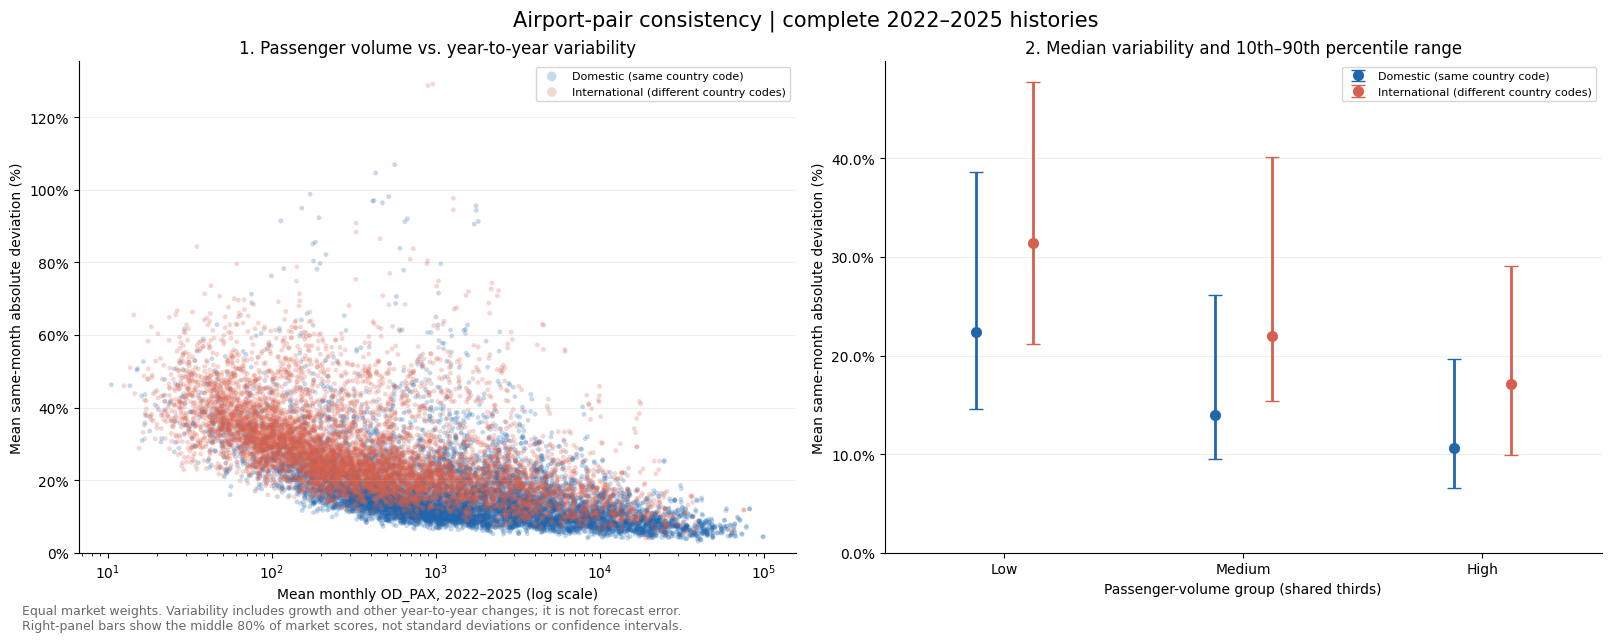

,volume_group,market_class,pair_count,median_monthly_pax,median_variability_pct,p10_variability_pct,p90_variability_pct
0,Low,Domestic (same country code),1610,187.45,22.40,14.62,38.62
1,Low,International (different country codes),3946,120.83,31.46,21.17,47.78
2,Medium,Domestic (same country code),3318,764.81,13.97,9.52,26.16
3,Medium,International (different country codes),2237,636.81,21.96,15.42,40.13
4,High,Domestic (same country code),4088,5043.99,10.58,6.61,19.61
5,High,International (different country codes),1468,3933.76,17.09,9.89,29.05


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import display

# Four complete calendar years: each month is compared across the same four years.
analysis_keys = ["ORG_AIRPRT", "DES_AIRPRT"]
analysis_pax = pax_forecasting.loc[
    pax_forecasting["DEP_YEAR"].between(2022, 2025),
    analysis_keys + ["DEP_YEAR", "DEP_MONTH", "OD_PAX"],
].copy()
if analysis_pax.duplicated(analysis_keys + ["DEP_YEAR", "DEP_MONTH"]).any():
    raise ValueError("Duplicate market-month records; review before analyzing.")
analysis_pax["valid_pax"] = np.isfinite(analysis_pax["OD_PAX"]) & analysis_pax["OD_PAX"].ge(0)
history_check = analysis_pax.groupby(analysis_keys).agg(
    observed_months=("OD_PAX", "size"), valid_months=("valid_pax", "sum")
)
complete_keys = history_check.index[
    history_check["observed_months"].eq(48) & history_check["valid_months"].eq(48)
]
complete_pax = analysis_pax.set_index(analysis_keys).loc[complete_keys].reset_index()

# For each pair and calendar month: mean absolute % deviation across years.
same_month_mean = complete_pax.groupby(analysis_keys + ["DEP_MONTH"])["OD_PAX"].transform("mean")
complete_pax["same_month_deviation_pct"] = (
    100 * (complete_pax["OD_PAX"] - same_month_mean).abs()
    / same_month_mean.where(same_month_mean.gt(0))
)
calendar_month_scores = complete_pax.groupby(analysis_keys + ["DEP_MONTH"])["same_month_deviation_pct"].mean()
pair_variability = calendar_month_scores.groupby(level=analysis_keys).agg(
    variability_pct="mean", scored_calendar_months="count"
)
pair_variability["mean_monthly_pax"] = complete_pax.groupby(analysis_keys)["OD_PAX"].mean()
# Require all 12 month scores; a zero mean has an undefined percentage deviation.
pair_variability = pair_variability.loc[pair_variability["scored_calendar_months"].eq(12)].reset_index()

country_lookup = airport_info.set_index("AIRPRT_CD")["CNTRY_CD"]
pair_variability["origin_country"] = pair_variability["ORG_AIRPRT"].map(country_lookup)
pair_variability["destination_country"] = pair_variability["DES_AIRPRT"].map(country_lookup)
if pair_variability[["origin_country", "destination_country"]].isna().any().any():
    raise ValueError("Missing country mappings; review before classifying markets.")
pair_variability["market_class"] = np.where(
    pair_variability["origin_country"].eq(pair_variability["destination_country"]),
    "Domestic (same country code)", "International (different country codes)",
)

# Shared volume thresholds across both classes, rather than separate class-specific bins.
volume_thresholds = pair_variability["mean_monthly_pax"].quantile([1/3, 2/3])
volume_labels = ["Low", "Medium", "High"]
pair_variability["volume_group"] = pd.cut(
    pair_variability["mean_monthly_pax"],
    bins=[-np.inf, volume_thresholds.iloc[0], volume_thresholds.iloc[1], np.inf],
    labels=volume_labels,
)
volume_variability_summary = (
    pair_variability.groupby(["volume_group", "market_class"], observed=True)
    .agg(pair_count=("variability_pct", "size"),
         median_monthly_pax=("mean_monthly_pax", "median"),
         median_variability_pct=("variability_pct", "median"),
         p10_variability_pct=("variability_pct", lambda s: s.quantile(0.10)),
         p90_variability_pct=("variability_pct", lambda s: s.quantile(0.90)))
    .reset_index()
)

print(f"Included {len(pair_variability):,} of {len(history_check):,} markets observed in 2022–2025.")
print(f"Excluded {len(history_check) - len(complete_keys):,} without 48 valid observations; "
      f"{len(complete_keys) - len(pair_variability):,} with undefined month-level percentage scores.")
print(f"Shared mean-monthly-volume cutoffs: Low ≤ {volume_thresholds.iloc[0]:,.1f}; "
      f"Medium ≤ {volume_thresholds.iloc[1]:,.1f}; High above that.")
print("Country classes follow the supplied codes; separately coded territories fall in the cross-code group.")

# View 1: one point per directional pair; View 2: median and 10th–90th percentiles.
fig, (scatter_ax, grouped_ax) = plt.subplots(1, 2, figsize=(16, 6), layout="constrained")
class_colors = {
    "Domestic (same country code)": "#2166ac",
    "International (different country codes)": "#d6604d",
}
for label, color in class_colors.items():
    points = pair_variability.loc[pair_variability["market_class"].eq(label)]
    scatter_ax.scatter(points["mean_monthly_pax"], points["variability_pct"],
                       s=12, alpha=0.25, color=color, edgecolors="none", label=label, rasterized=True)
scatter_ax.set_xscale("log")
scatter_ax.set_xlabel("Mean monthly OD_PAX, 2022–2025 (log scale)")
scatter_ax.set_ylabel("Mean same-month absolute deviation (%)")
scatter_ax.set_title("1. Passenger volume vs. year-to-year variability")
scatter_ax.legend(fontsize=8, loc="upper right", markerscale=2)

for offset, (label, color) in zip([-0.12, 0.12], class_colors.items()):
    group_stats = (volume_variability_summary.loc[volume_variability_summary["market_class"].eq(label)]
                   .set_index("volume_group").reindex(volume_labels))
    medians = group_stats["median_variability_pct"]
    grouped_ax.errorbar(
        np.arange(3) + offset, medians,
        yerr=[medians - group_stats["p10_variability_pct"], group_stats["p90_variability_pct"] - medians],
        fmt="o", markersize=7, capsize=5, linewidth=2, color=color, label=label,
    )
grouped_ax.set_xticks(range(3), volume_labels)
grouped_ax.set_xlim(-0.5, 2.5)
grouped_ax.set_xlabel("Passenger-volume group (shared thirds)")
grouped_ax.set_ylabel("Mean same-month absolute deviation (%)")
grouped_ax.set_title("2. Median variability and 10th–90th percentile range")
grouped_ax.legend(fontsize=8, loc="upper right")
for ax in (scatter_ax, grouped_ax):
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Airport-pair consistency | complete 2022–2025 histories", fontsize=15)
fig.text(0.01, -0.04,
         "Equal market weights. Variability includes growth and other year-to-year changes; it is not forecast error.\n"
         "Right-panel bars show the middle 80% of market scores, not standard deviations or confidence intervals.",
         fontsize=9, color="dimgray")
plt.show()
display(volume_variability_summary.round(2))


### How each airport pair's deviation is calculated

Let $x_{p,m,y}$ be `OD_PAX` for directional airport pair $p$, calendar month $m$, and year $y$. We use $Y=\{2022,2023,2024,2025\}$, so each included pair has all 48 monthly observations.

**1. Find the same-month average across the four years.**

$$
\mu_{p,m}=\frac{1}{4}\sum_{y\in Y}x_{p,m,y}
$$

For example, January's average uses January 2022, January 2023, January 2024, and January 2025 only.

**2. Calculate that month's mean absolute percentage deviation.**

$$
d_{p,m}=\frac{1}{4}\sum_{y\in Y}
\left(100\frac{|x_{p,m,y}-\mu_{p,m}|}{\mu_{p,m}}\right)
$$

Each year's difference is measured relative to that pair's same-month average. Absolute values prevent above-average and below-average observations from cancelling out. For January values of 80, 100, 100, and 120, the mean is 100 and the absolute percentage deviations are 20%, 0%, 0%, and 20%, giving $d_{p,\mathrm{Jan}}=10\%$.

**3. Average the 12 monthly deviation scores to get the dot's vertical position.**

$$
D_p=\frac{1}{12}\sum_{m=1}^{12}d_{p,m}
$$

Every calendar month gets equal weight. Thus **one dot represents one directional airport pair, not a single month**. A value of $D_p=20\%$ means that, averaged across calendar months and years, passenger volumes differ from their respective same-month averages by 20%.

**4. Calculate the dot's horizontal position: average monthly passenger volume.**

$$
V_p=\frac{1}{48}\sum_{m=1}^{12}\sum_{y\in Y}x_{p,m,y}
$$

The scatterplot displays $(V_p,D_p)$, with a logarithmic horizontal axis. Blue indicates the same origin/destination country code; red indicates different country codes, using the supplied airport reference.

**Grouped view.** We divide pairs into low-, medium-, and high-volume groups using the 33⅓ and 66⅔ percentiles of $V_p$ across all included pairs. These thresholds are shared by both country classes. Within each volume group and class, the plotted point is the **median** of $D_p$, and the bar extends from its **10th to 90th percentile**. These bars are not standard deviations or confidence intervals.

**Interpretation and exclusions.** This measures historical same-month consistency, not forecast error or statistical variance. Growth, recovery, and other year-to-year changes contribute to it. It does not compare January with July. Only complete 2022–2025 histories with finite, nonnegative values and positive means for all 12 calendar months are included; missing observations are not filled with zero. The source data still retains other years.


Growth analysis: 16,667 directional markets with complete 2022–2025 histories.
Consistently growing/declining means all three annual changes have that sign, with no significance threshold.
CAGR = 100 × [(2025 passengers / 2022 passengers)^(1/3) − 1]. It summarizes endpoints, not the path between them.
The variability score is unchanged; this analysis has not removed trends or estimated unpredictable noise.
Full pair-level results: growth_summary. Grouped counts and medians:


,market_class,volume_group,growth_pattern,pair_count,median_cagr_pct,median_variability_pct
0,Domestic (same country code),Low,Consistently declining,37,-9.59,23.35
1,Domestic (same country code),Low,Consistently growing,397,17.07,24.26
2,Domestic (same country code),Low,Mixed / flat,1176,5.10,21.97
3,Domestic (same country code),Medium,Consistently declining,77,-9.96,18.41
4,Domestic (same country code),Medium,Consistently growing,776,11.30,15.15
5,Domestic (same country code),Medium,Mixed / flat,2465,3.80,13.62
6,Domestic (same country code),High,Consistently declining,181,-8.26,12.22
7,Domestic (same country code),High,Consistently growing,757,10.79,12.30
8,Domestic (same country code),High,Mixed / flat,3150,2.28,10.13
9,International (different country codes),Low,Consistently declining,25,-11.97,28.98


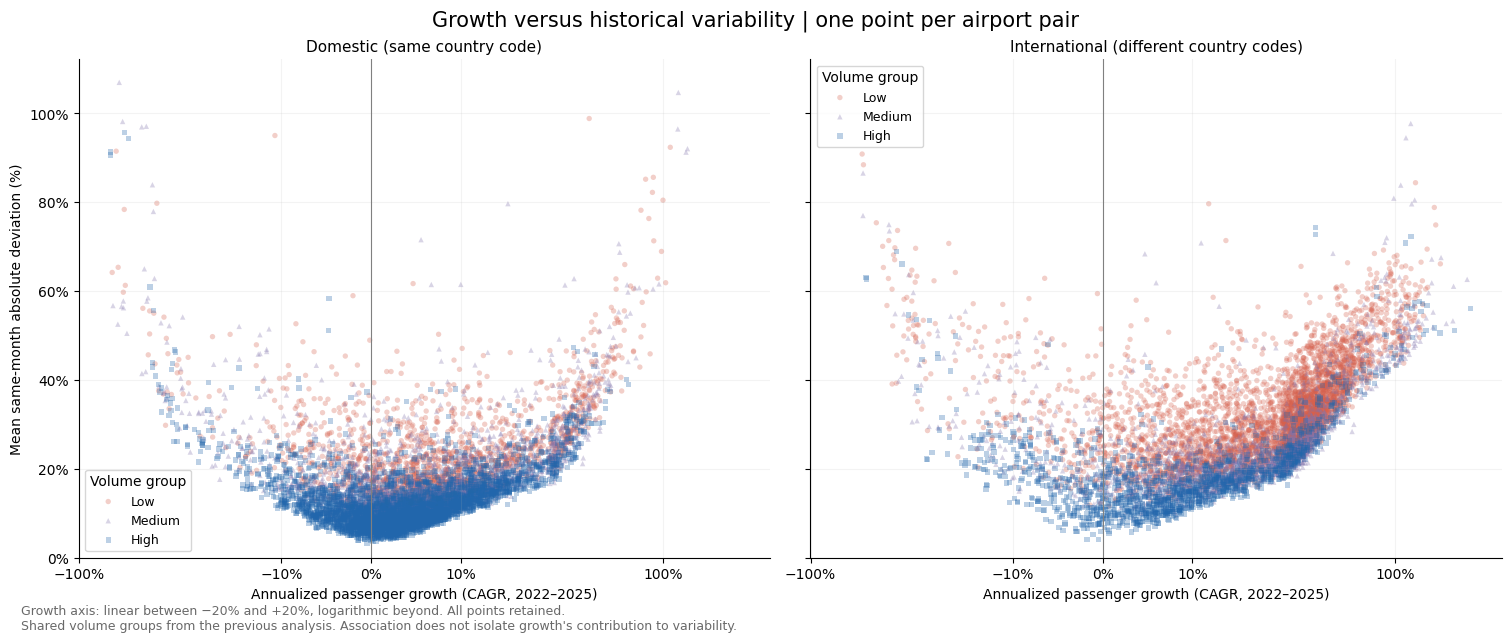

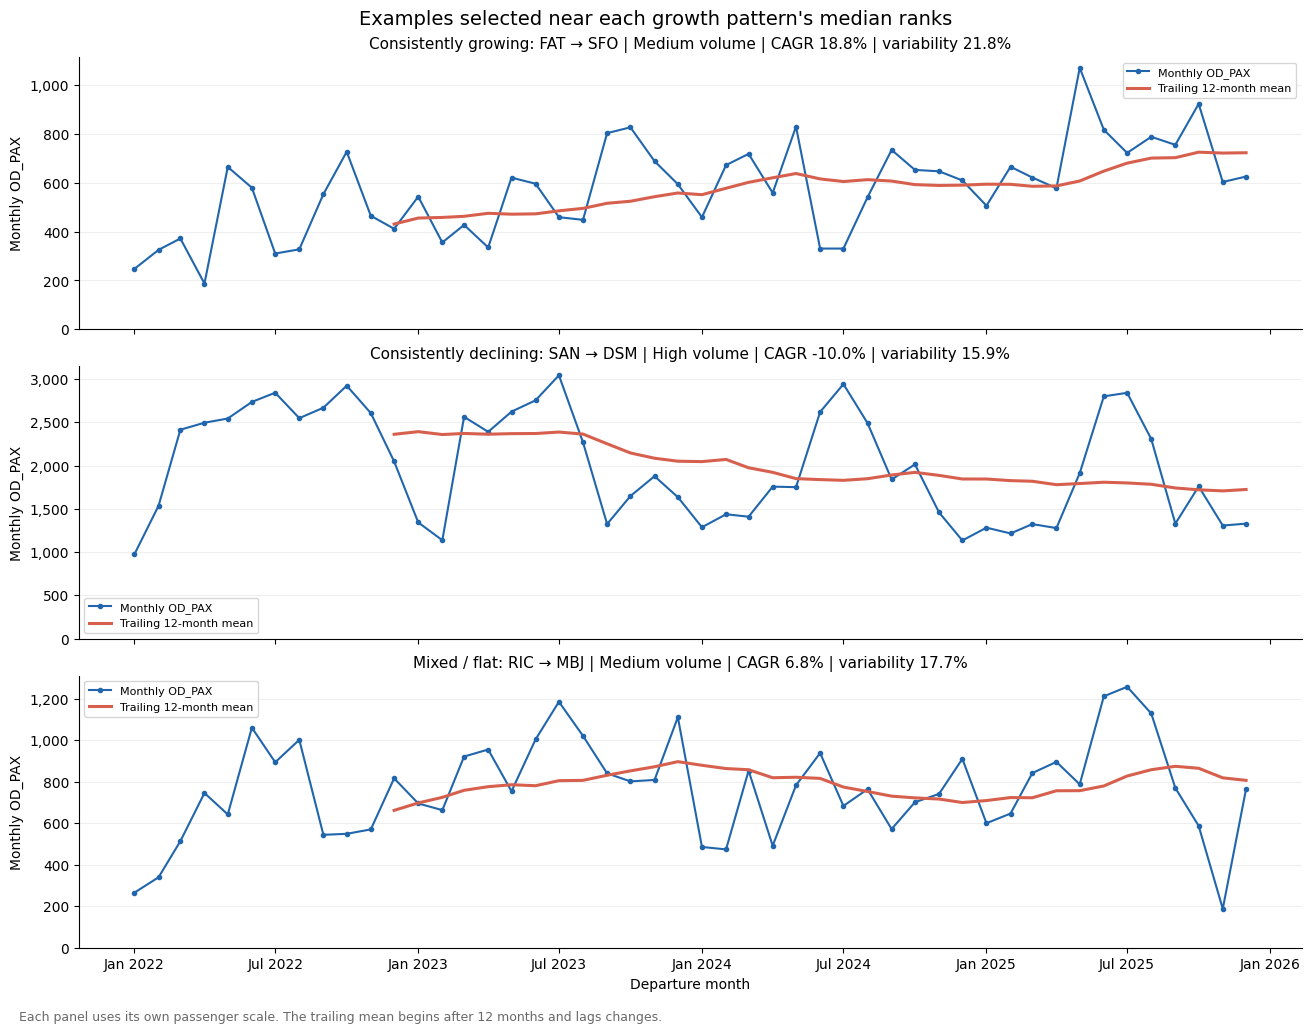

,market,market_class,volume_group,growth_pattern,pax_2022,pax_2023,pax_2024,pax_2025,growth_2023_pct,growth_2024_pct,growth_2025_pct,cagr_2022_2025_pct,variability_pct
4616,FAT → SFO,Domestic (same country code),Medium,Consistently growing,5174.98,6704.91,7090.86,8685.38,29.56,5.76,22.49,18.84,21.77
13128,SAN → DSM,Domestic (same country code),High,Consistently declining,28346.98,24611.82,22142.62,20685.55,-13.18,-10.03,-6.58,-9.97,15.86
12553,RIC → MBJ,International (different country codes),Medium,Mixed / flat,7939.39,10754.52,8393.44,9674.26,35.46,-21.95,15.26,6.81,17.70


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import display

# Run the volume-versus-variability cell first: reuse its complete 2022–2025 cohort.
growth_keys = ["ORG_AIRPRT", "DES_AIRPRT"]
annual_pax = (
    complete_pax.groupby(growth_keys + ["DEP_YEAR"])["OD_PAX"]
    .sum(min_count=1).unstack("DEP_YEAR").reindex(columns=[2022, 2023, 2024, 2025])
)
growth_summary = pair_variability.merge(
    annual_pax.rename(columns={year: f"pax_{year}" for year in annual_pax.columns}).reset_index(),
    on=growth_keys, how="left", validate="one_to_one",
)
annual_columns = [f"pax_{year}" for year in range(2022, 2026)]
if growth_summary[annual_columns].isna().any().any() or growth_summary[annual_columns].le(0).any().any():
    raise ValueError("Annual growth requires complete, positive annual totals.")

# Three year-to-year changes, plus annualized change over three annual intervals.
yoy_columns = []
for year in [2023, 2024, 2025]:
    column = f"growth_{year}_pct"
    growth_summary[column] = 100 * (growth_summary[f"pax_{year}"] / growth_summary[f"pax_{year-1}"] - 1)
    yoy_columns.append(column)
growth_summary["cagr_2022_2025_pct"] = (
    100 * ((growth_summary["pax_2025"] / growth_summary["pax_2022"]) ** (1/3) - 1)
)
growth_summary["growth_pattern"] = np.select(
    [growth_summary[yoy_columns].gt(0).all(axis=1), growth_summary[yoy_columns].lt(0).all(axis=1)],
    ["Consistently growing", "Consistently declining"], default="Mixed / flat",
)
growth_summary["market"] = growth_summary["ORG_AIRPRT"] + " → " + growth_summary["DES_AIRPRT"]
growth_group_summary = (
    growth_summary.groupby(["market_class", "volume_group", "growth_pattern"], observed=True)
    .agg(pair_count=("market", "size"),
         median_cagr_pct=("cagr_2022_2025_pct", "median"),
         median_variability_pct=("variability_pct", "median"))
    .reset_index()
)

# Choose one example per pattern, before plotting, near the pattern's median
# ranks for volume, CAGR, and variability. This avoids selecting extreme examples.
pattern_order = ["Consistently growing", "Consistently declining", "Mixed / flat"]
selected_indices = []
for pattern in pattern_order:
    candidates = growth_summary.loc[growth_summary["growth_pattern"].eq(pattern)]
    if candidates.empty:
        continue
    median_rank_distance = (
        candidates[["mean_monthly_pax", "cagr_2022_2025_pct", "variability_pct"]]
        .rank(pct=True).sub(0.5).abs().sum(axis=1)
    )
    selected_indices.append(median_rank_distance.idxmin())
growth_examples = growth_summary.loc[selected_indices].copy()
growth_example_series = {}
for _, example in growth_examples.iterrows():
    selected = complete_pax.loc[
        complete_pax["ORG_AIRPRT"].eq(example["ORG_AIRPRT"])
        & complete_pax["DES_AIRPRT"].eq(example["DES_AIRPRT"])
    ].copy()
    selected["month"] = pd.to_datetime(dict(year=selected["DEP_YEAR"], month=selected["DEP_MONTH"], day=1))
    growth_example_series[example["market"]] = selected.set_index("month")["OD_PAX"].sort_index()

print(f"Growth analysis: {len(growth_summary):,} directional markets with complete 2022–2025 histories.")
print("Consistently growing/declining means all three annual changes have that sign, with no significance threshold.")
print("CAGR = 100 × [(2025 passengers / 2022 passengers)^(1/3) − 1]. It summarizes endpoints, not the path between them.")
print("The variability score is unchanged; this analysis has not removed trends or estimated unpredictable noise.")
print("Full pair-level results: growth_summary. Grouped counts and medians:")
display(growth_group_summary.round(2))

# Graph 1: separate panels for country class; markers/colors distinguish volume groups.
classes = ["Domestic (same country code)", "International (different country codes)"]
volume_styles = {"Low": ("#d6604d", "o"), "Medium": ("#8073ac", "^"), "High": ("#2166ac", "s")}
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True, layout="constrained")
for ax, market_class in zip(axes, classes):
    class_data = growth_summary.loc[growth_summary["market_class"].eq(market_class)]
    for volume, (color, marker) in volume_styles.items():
        points = class_data.loc[class_data["volume_group"].eq(volume)]
        ax.scatter(points["cagr_2022_2025_pct"], points["variability_pct"],
                   s=15, alpha=0.3, color=color, marker=marker, edgecolors="none", label=volume, rasterized=True)
    # Preserve all observations, including high growth from small starting totals.
    ax.set_xscale("symlog", linthresh=20)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_ylim(bottom=0)
    ax.set_title(market_class, fontsize=11)
    ax.set_xlabel("Annualized passenger growth (CAGR, 2022–2025)")
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(title="Volume group", fontsize=9)
axes[0].set_ylabel("Mean same-month absolute deviation (%)")
fig.suptitle("Growth versus historical variability | one point per airport pair", fontsize=15)
fig.text(0.01, -0.04,
         "Growth axis: linear between −20% and +20%, logarithmic beyond. All points retained.\n"
         "Shared volume groups from the previous analysis. Association does not isolate growth's contribution to variability.",
         fontsize=9, color="dimgray")
plt.show()

# Graph 2: continuous monthly series, one descriptive example per growth pattern.
fig, axes = plt.subplots(len(growth_examples), 1, figsize=(13, 3.3 * len(growth_examples)),
                         sharex=True, squeeze=False, layout="constrained")
for ax, (_, example) in zip(axes[:, 0], growth_examples.iterrows()):
    series = growth_example_series[example["market"]]
    ax.plot(series.index, series.values, color="#2166ac", linewidth=1.5, marker="o", markersize=3,
            label="Monthly OD_PAX")
    ax.plot(series.index, series.rolling(12, min_periods=12).mean(), color="#d6604d", linewidth=2.2,
            label="Trailing 12-month mean")
    ax.set_title(f"{example['growth_pattern']}: {example['market']} | {example['volume_group']} volume | "
                 f"CAGR {example['cagr_2022_2025_pct']:.1f}% | variability {example['variability_pct']:.1f}%", fontsize=11)
    ax.set_ylabel("Monthly OD_PAX")
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8)
axes[-1, 0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[-1, 0].set_xlabel("Departure month")
fig.suptitle("Examples selected near each growth pattern's median ranks", fontsize=14)
fig.text(0.01, -0.025, "Each panel uses its own passenger scale. The trailing mean begins after 12 months and lags changes.",
         fontsize=9, color="dimgray")
plt.show()
display(growth_examples[["market", "market_class", "volume_group", "growth_pattern"]
                        + annual_columns + yoy_columns + ["cagr_2022_2025_pct", "variability_pct"]].round(2))


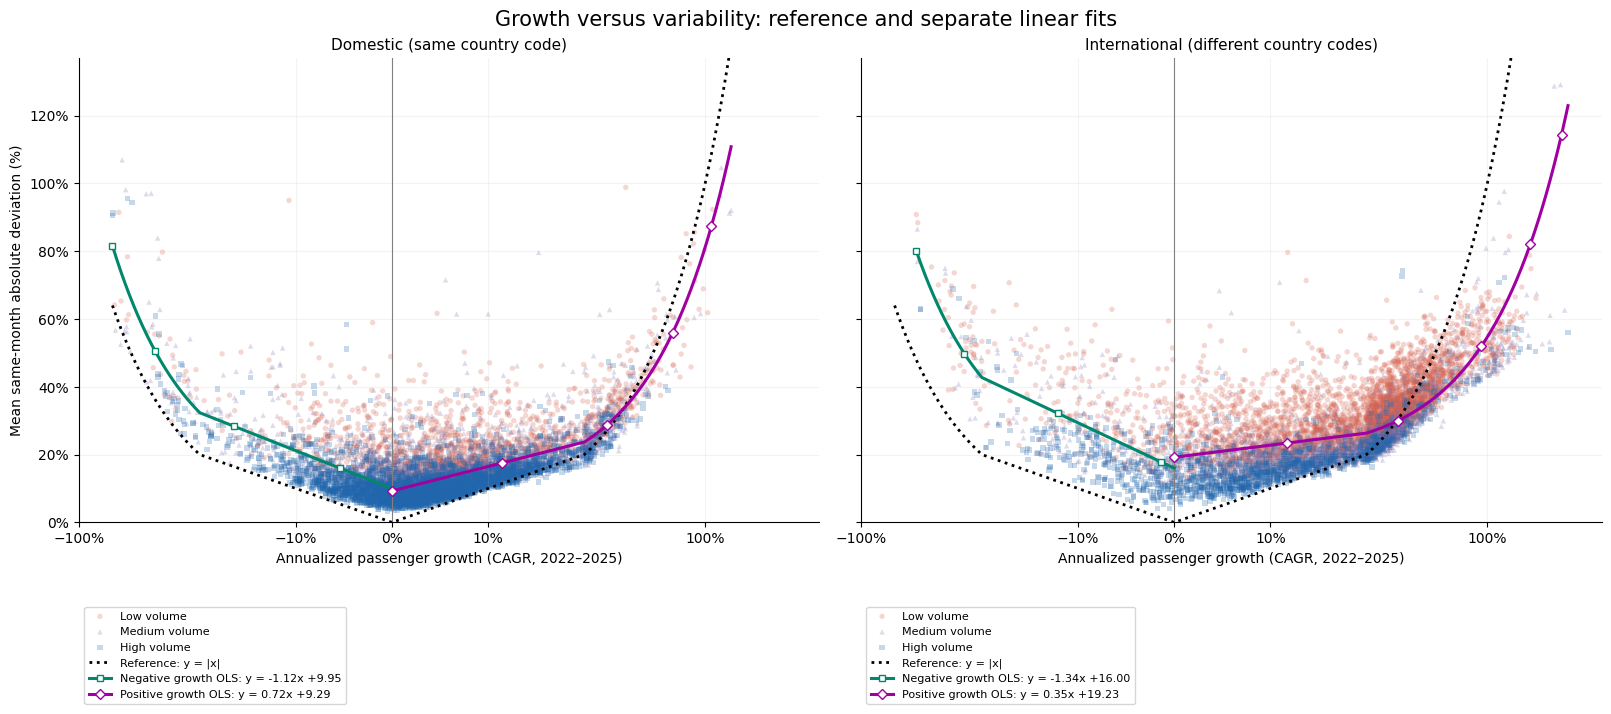

OLS = ordinary least squares; each pair has equal weight. Fits combine all volume groups within each country class.
Negative and positive growth are fitted separately, with free intercepts; zero-growth pairs are plotted but excluded from both fits.
Fits use raw percentage values. The x-axis is linear within ±20% and logarithmic beyond, so straight relationships may look curved.
The dotted y = |x| line is a reference, not a theoretical identity. Lines clip at the displayed y-range; no market points are omitted.
R² measures descriptive in-sample fit, not forecast accuracy or evidence of causation. Large-growth observations can strongly influence OLS.


,market_class,direction,pair_count,slope,intercept_pct,r_squared
0,Domestic (same country code),Negative growth,2214,-1.120,9.950,0.563
1,Domestic (same country code),Positive growth,6802,0.719,9.292,0.607
2,International (different country codes),Negative growth,800,-1.336,16.004,0.525
3,International (different country codes),Positive growth,6851,0.355,19.231,0.555


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Run the preceding growth analysis first. x and y are percentage-point values.
# Fit straight lines in the ORIGINAL values, not in log-transformed coordinates.
fit_classes = ["Domestic (same country code)", "International (different country codes)"]
fit_volume_styles = {"Low": ("#d6604d", "o"), "Medium": ("#8073ac", "^"), "High": ("#2166ac", "s")}
growth_fit_data = growth_summary.loc[
    np.isfinite(growth_summary["cagr_2022_2025_pct"])
    & np.isfinite(growth_summary["variability_pct"])
].copy()
fit_results = []
fit_curves = {}
for market_class in fit_classes:
    class_data = growth_fit_data.loc[growth_fit_data["market_class"].eq(market_class)]
    for direction in ["Negative growth", "Positive growth"]:
        condition = class_data["cagr_2022_2025_pct"].lt(0) if direction == "Negative growth" else class_data["cagr_2022_2025_pct"].gt(0)
        subset = class_data.loc[condition]
        x = subset["cagr_2022_2025_pct"].to_numpy()
        y = subset["variability_pct"].to_numpy()
        if len(x) < 2 or np.unique(x).size < 2:
            continue
        slope, intercept = np.polyfit(x, y, deg=1)
        fitted = slope * x + intercept
        ss_total = np.sum((y - y.mean()) ** 2)
        r_squared = 1 - np.sum((y - fitted) ** 2) / ss_total if ss_total > 0 else np.nan
        # Dense grid, including values near zero, renders the symlog axis correctly.
        grid = np.linspace(x.min(), x.max(), 2000)
        fit_curves[(market_class, direction)] = (grid, slope * grid + intercept, slope, intercept)
        fit_results.append({"market_class": market_class, "direction": direction,
                            "pair_count": len(x), "slope": slope, "intercept_pct": intercept,
                            "r_squared": r_squared})
growth_fit_summary = pd.DataFrame(fit_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True, layout="constrained")
x_min = min(float(growth_fit_data["cagr_2022_2025_pct"].min()), 0)
x_max = max(float(growth_fit_data["cagr_2022_2025_pct"].max()), 0)
reference_x = np.unique(np.concatenate([np.linspace(x_min, 0, 2000), np.linspace(0, x_max, 2000)]))
fit_styles = {"Negative growth": ("#00876c", "s"), "Positive growth": ("#a000a0", "D")}

for ax, market_class in zip(axes, fit_classes):
    points = growth_fit_data.loc[growth_fit_data["market_class"].eq(market_class)]
    for volume, (color, marker) in fit_volume_styles.items():
        group = points.loc[points["volume_group"].eq(volume)]
        ax.scatter(group["cagr_2022_2025_pct"], group["variability_pct"],
                   s=15, alpha=0.25, color=color, marker=marker, edgecolors="none",
                   label=f"{volume} volume", rasterized=True)
    ax.plot(reference_x, np.abs(reference_x), color="black", linestyle=":", linewidth=2,
            label="Reference: y = |x|", zorder=4)
    for direction, (color, marker) in fit_styles.items():
        result = fit_curves.get((market_class, direction))
        if result is None:
            continue
        grid, line, slope, intercept = result
        label = f"{direction} OLS: y = {slope:.2f}x {intercept:+.2f}"
        ax.plot(grid, line, color=color, linewidth=2.2, marker=marker,
                markevery=0.13, markersize=5, markerfacecolor="white", label=label, zorder=5)
    ax.set_xscale("symlog", linthresh=20)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.axvline(0, color="gray", linewidth=0.8)
    # Keep the scatter's data range readable; reference/fit lines clip at the bounds.
    ax.set_ylim(0, growth_fit_data["variability_pct"].max() * 1.06)
    ax.set_title(market_class, fontsize=11)
    ax.set_xlabel("Annualized passenger growth (CAGR, 2022–2025)")
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.17))
axes[0].set_ylabel("Mean same-month absolute deviation (%)")
fig.suptitle("Growth versus variability: reference and separate linear fits", fontsize=15)
plt.show()

print("OLS = ordinary least squares; each pair has equal weight. Fits combine all volume groups within each country class.")
print("Negative and positive growth are fitted separately, with free intercepts; zero-growth pairs are plotted but excluded from both fits.")
print("Fits use raw percentage values. The x-axis is linear within ±20% and logarithmic beyond, so straight relationships may look curved.")
print("The dotted y = |x| line is a reference, not a theoretical identity. Lines clip at the displayed y-range; no market points are omitted.")
print("R² measures descriptive in-sample fit, not forecast accuracy or evidence of causation. Large-growth observations can strongly influence OLS.")
display(growth_fit_summary.round(3))
